# LofSRCR / Weight-Space Programming (WSP) demo

This notebook demonstrates the modular repository:

1. Initialize Ministral through an Ollama endpoint.
2. Run an ACE BCC compression scan using the test-bed utilities.
3. Diagnose compression artifacts.


## 0. Configuration

Set paths for the ACE YAML files and (for coefficient-space operations) the verified permutation file. Environment variables keep machine-specific paths out of source code.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path("")



sys.path.insert(0, str(REPO_ROOT))

from ministral_runtime import OllamaConfig, OllamaRuntime
from lofsrcr_utils import run_compression_test

print("Imports successful.")

2026-11-07 21:23:50,755 - numexpr.utils - INFO - Note: NumExpr detected 40 cores but "NUMEXPR_MAX_THREADS" not set, so enforcing safe limit of 16.
2026-11-07 21:23:50,756 - numexpr.utils - INFO - NumExpr defaulting to 16 threads.


Imports successful.


/cmmc/ptmp/pyironhb/mambaforge/envs/pyiron_mpie_cmti_2026-10-13/lib/python3.12/site-packages/pyace/multispecies_basisextension.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
import os
from pathlib import Path

# Repository root: parent of notebooks/
REPO_ROOT = Path.cwd().parent

# All project data paths are relative to the repository root
PROJECT_DATA = REPO_ROOT

POTENTIAL_DIR = (
    PROJECT_DATA / "potentials" / "Fe_ACE" / "yamls"
)

PERMUTATION_PATH = (
    PROJECT_DATA / "wsp" / "coefficient_permutation.npz"
)

OUTPUT_DIR = PROJECT_DATA / "results" / "compression_scans"

MODEL_PATHS = {
    "FeO_ACE": POTENTIAL_DIR / "ACE_Fe-O.yaml",
    "FeOH_ACE": POTENTIAL_DIR / "ACE_Fe-O-H.yaml",
}

# Check paths before running
print("Repository:", REPO_ROOT)
print("Potential directory:", POTENTIAL_DIR)

for name, path in MODEL_PATHS.items():
    print(f"{name}: {path} | exists={path.is_file()}")

print("Permutation file:", PERMUTATION_PATH)

Repository: /cmmc/u/vnair/Documents/WSP/wsp2Test
Potential directory: /cmmc/u/vnair/Documents/WSP/wsp2Test/potentials/Fe_ACE/yamls
FeO_ACE: /cmmc/u/vnair/Documents/WSP/wsp2Test/potentials/Fe_ACE/yamls/ACE_Fe-O.yaml | exists=True
FeOH_ACE: /cmmc/u/vnair/Documents/WSP/wsp2Test/potentials/Fe_ACE/yamls/ACE_Fe-O-H.yaml | exists=True
Permutation file: /cmmc/u/vnair/Documents/WSP/wsp2Test/wsp/coefficient_permutation.npz


## 1. Initialize Ministral

The runtime can either connect to an existing Ollama server or start a server process on the current node. On a cluster, use the endpoint and process model approved by the cluster administrators.

In [3]:

OLLAMA_MODEL = os.environ.get("OLLAMA_MODEL", "ministral-3:8b")
OLLAMA_URL = os.environ.get("OLLAMA_URL")  # e.g. http://node-name:11434

ministral = OllamaRuntime(
    OllamaConfig(
        model=OLLAMA_MODEL,
        base_url=OLLAMA_URL,
        ollama_bin=os.environ.get("OLLAMA_BIN"),
        host=os.environ.get("OLLAMA_HOST", "0.0.0.0"),
        port=int(os.environ.get("OLLAMA_PORT", "11434")),
    )
)

print("Ollama endpoint:", ministral.base_url)

Ollama endpoint: http://cmti001.bc.mpcdf.mpg.de:11434


In [4]:
# If Ollama is already running, skip start_server().
# Otherwise uncomment the next line to start it on this node:
# pid = ministral.start_server(log_path="ollama.log")
# print("Ollama PID:", pid)

server_info = ministral.wait_until_ready(attempts=30, interval=2)
print("Ollama server is responding.")
print("Available models:", [item.get("name") for item in server_info.get("models", [])])

Ollama server is responding.
Available models: ['ministral-3:3b', 'ministral-3:8b']


In [5]:
load_result = ministral.load_model()
print("Model warmed:", load_result.get("model", OLLAMA_MODEL))
print("Load duration (s):", load_result.get("load_duration", 0) / 1e9)

Model warmed: ministral-3:8b
Load duration (s): 0.0


In [6]:
smoke_test = ministral.generate(
    "Respond with exactly: WSP operational.",
    options={"temperature": 0, "num_predict": 50},
    timeout=3600,
)
print(smoke_test.get("response", ""))

Model,ministral-3:8b
Python wall time,62.58 s
Total inference,62.56 s
Model loading,0.00 s
Prompt processing,2.06 s
Prompt rate,273.44 tokens/s
Text generation,60.48 s
Generation rate,0.08 tokens/s
Input tokens,562
Output tokens,5
Completion reason,stop


WSP operational.


## 2. Run the ACE compression test bed

The default settings reproduce the notebook's BCC Fe test: lattice constant 2.8665 Å, a 3×3×3 supercell, 80% maximum compression, and 300 intervals. Adjust these only deliberately; record the values with each run.

In [7]:
from lofsrcr_utils import run_compression_test

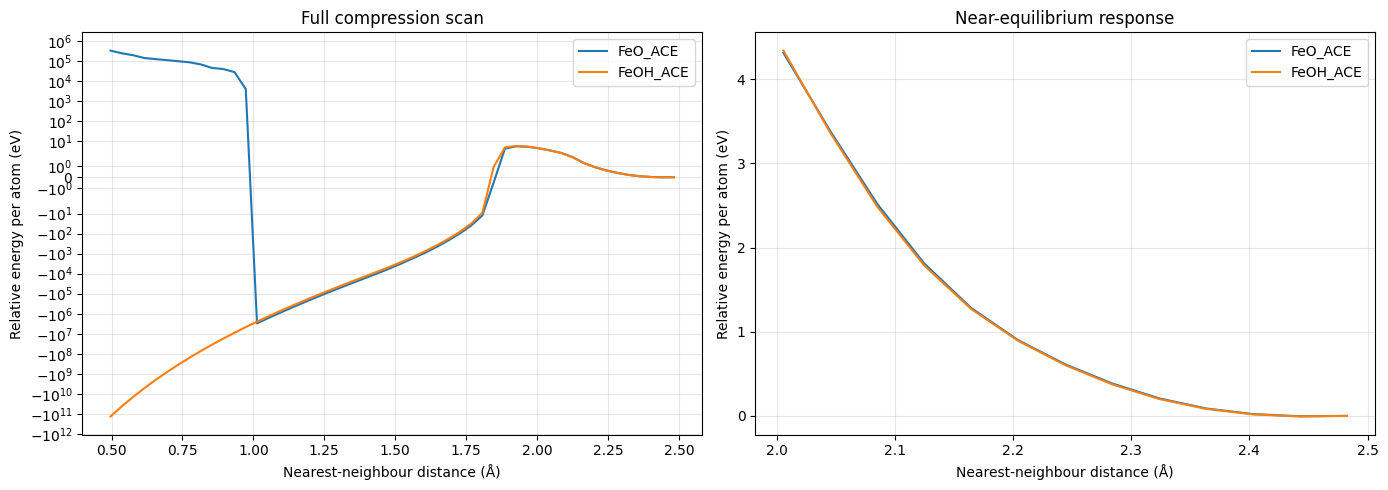

Results saved to: /cmmc/u/vnair/Documents/WSP/wsp2Test/results/compression_scans/Fe_ACE_comparison


In [9]:
models_to_run = ["FeO_ACE", "FeOH_ACE"]

scan = run_compression_test(
    models=models_to_run,
    model_paths=MODEL_PATHS,
    run_name="Fe_ACE_comparison",
    output_dir=OUTPUT_DIR,
    element="Fe",
    lattice_constant=2.8665,
    supercell_size=(3, 3, 3),
    max_compression=0.80,
    n_steps=50,
)

results = scan["results"]
print("Results saved to:", scan["run_dir"])

## 3. Diagnose compression response

The diagnostic sorts points from the largest nearest-neighbour distance to the smallest, i.e. progressive compression. A negative adjacent energy difference on the post-equilibrium branch is counted as a monotonicity violation.

In [10]:
from lofsrcr_utils import (
    diagnose_compression_curve,
    inspect_largest_energy_changes,
    identify_violation_regions,
    build_diagnostic_payload,
)

In [11]:
baseline_diagnostics = {
    model: diagnose_compression_curve(results, model)
    for model in models_to_run
}
violation_regions = {
    model: identify_violation_regions(results, model)
    for model in models_to_run
}

for model in models_to_run:
    print("\\n", model)
    for key, value in baseline_diagnostics[model].items():
        if key != "model":
            print(f"{key}: {value}")
    print("Largest energy changes:")
    for row in inspect_largest_energy_changes(results, model, n=5):
        print(row)
    print("Violation regions:", violation_regions[model][:5])

\n FeO_ACE
equilibrium_distance: 2.4427424308289223
equilibrium_energy: -0.004209200614524455
compressed_points: 49
monotonicity_violations: 23
monotonicity_violation_fraction: 0.4791666666666667
total_decreasing_energy: 3022670.901228773
largest_energy_decrease: 1371642.4485655294
largest_absolute_energy_jump: 3026518.594406254
finite_energy: True
Largest energy changes:
{'index': 37, 'distance_before': 1.0128444225388211, 'distance_after': 0.9731250334196517, 'energy_change': 3026518.594406254}
{'index': 36, 'distance_before': 1.0525638116579912, 'distance_after': 1.0128444225388211, 'energy_change': -1371642.4485655294}
{'index': 35, 'distance_before': 1.0922832007771606, 'distance_after': 1.0525638116579912, 'energy_change': -732102.6236994136}
{'index': 34, 'distance_before': 1.1320025898963304, 'distance_after': 1.0922832007771606, 'energy_change': -398673.31934378116}
{'index': 33, 'distance_before': 1.1717219790155, 'distance_after': 1.1320025898963304, 'energy_change': -221123

## 4. Build a physical diagnostic payload for Ministral

The payload reports measured curve behaviour. It does not claim to identify the responsible ACE basis functions; that requires basis-resolved energy/sensitivity analysis.

In [12]:
payload_FeO = build_diagnostic_payload(
    "FeO_ACE",
    violation_regions,
    baseline_diagnostics,
)
print(payload_FeO)

{'task': 'ACE compression-response diagnosis', 'model': 'FeO_ACE', 'physical_expectation': {'equilibrium': 'A local energy minimum near equilibrium.', 'post_equilibrium': 'Energy should increase as interatomic distance decreases.', 'potential_artifacts': ['secondary minima', 'energy decreases during compression', 'discontinuities', 'runaway energy collapse']}, 'baseline': {'equilibrium_distance_angstrom': 2.4427424308289223, 'equilibrium_energy_ev_per_atom': -0.004209200614524455, 'monotonicity_violation_fraction': 0.4791666666666667, 'total_decreasing_energy_ev_per_atom': 3022670.901228773, 'largest_energy_decrease_ev_per_atom': 1371642.4485655294, 'largest_energy_jump_ev_per_atom': 3026518.594406254}, 'artifact_regions': [{'start_index': 14, 'end_index': 37, 'distance_start': 1.9263903722797213, 'distance_end': 1.0128444225388211, 'number_of_intervals': 23, 'total_energy_decrease': 3022670.9012287734, 'largest_single_decrease': 1371642.4485655294}, {'start_index': 0, 'end_index': 1, 